# Fleet Assignment Project

By David Madden and Alexander Putivskii.

In [2]:
import csv
from ortools.math_opt.python import mathopt
from collections import Counter
import networkx as nx
import matplotlib.pyplot as plt

plt.style.use("default")

## Data unpacking

In [3]:
def minutes(time):
    hour, minute = map(int, time.split(":"))
    return (60 * hour + minute) % 1440

In [23]:
# Aircraft types: K
K = {}
with open("aircraft_data.csv", encoding="utf-8-sig", newline="") as file:
    for row in csv.DictReader(file):
        if not row["Type No"]:
            continue
        j = int(row["Type No"])
        K[j] = {
            "N": int(row["Number of Aircrafts"]),
            "range_km": float(row["Max Range, km"]),
            "takeoff_kg": float(row["Fuel Consumption Take-off, kg"]),
            "cruise_kg_per_km": float(row["Fuel Consumption Cruise, kg/km"]),
            "fuel_type": row["Fuel Type"],
            "fuel_price_gbp_per_kg": float(row["Fuel Cost, £/kg, aip.aero"]),
        }

# Flights: F
F = []
with open("flights.csv", encoding="utf-8-sig", newline="") as file:
    for row in csv.DictReader(file):
        if row["id"] not in ["28","42","49","92","118"]:
            F.append({
                "id": row["id"],
                "origin": row["origin"],
                "destination": row["destination"],
                "departure": row["departure"],
                "arrival": row["arrival"],
            })

# Airports: M (alphabetical order)
M = sorted({f["origin"] for f in F} | {f["destination"] for f in F})

# Airport-to-airport distances
airport_distances = {}
with open("airport_distances.csv", encoding="utf-8-sig", newline="") as file:
    for origin, destination, distance in csv.reader(file):
        airport_distances[origin, destination] = float(distance)

distances_km = {
    f["id"]: airport_distances[f["origin"], f["destination"]]
    for f in F
}

# Time-nodes: T (built from the flights)
T = {airport: [] for airport in M}
for f in F:
    T[f["origin"]].append((minutes(f["departure"]), -1, f["id"]))
    T[f["destination"]].append((minutes(f["arrival"]), 1, f["id"]))

for airport in M:
    T[airport].sort(key=lambda event: (event[0], event[1]))

print("Flights:", len(F))
print("Aircraft types:", len(K))
print("Available aircraft:", sum(a["N"] for a in K.values()))
print("Airports:", len(M))
print("Time-nodes:", sum(len(events) for events in T.values()))
print("First flight:", F[0])
print(f"First events at {M[0]}:", T[M[0]][:3])

Flights: 163
Aircraft types: 7
Available aircraft: 35
Airports: 36
Time-nodes: 326
First flight: {'id': '0', 'origin': 'ABZ', 'destination': 'NWI', 'departure': '14:25', 'arrival': '15:45'}
First events at ABZ: [(395, -1, '20'), (400, -1, '2'), (400, -1, '24')]


## Solver

In [24]:
def solve_fleet_assignment(F, K, M, T, distances_km):
    flights = [f["id"] for f in F]
    types = list(K)
    model = mathopt.Model(name="FleetAssignment")

    # Decision variables
    x = {}
    for i in flights:
        for j in types:
            x[i, j] = model.add_binary_variable(name=f"x_{i}_{j}")

    G = {}
    for m in M:
        for t in range(len(T[m])):
            for j in types:
                G[m, t, j] = model.add_integer_variable(
                    lb=0, name=f"G_{m}_{t}_{j}"
                )

    # Fuel costs
    C = {}
    for i in flights:
        for j in types:
            a = K[j]
            fuel = a["takeoff_kg"] + a["cruise_kg_per_km"] * distances_km[i]
            C[i, j] = fuel * a["fuel_price_gbp_per_kg"]

    model.minimize(mathopt.fast_sum(
        C[i, j] * x[i, j] for i in flights for j in types
    ))

    # Each flight is assigned to one aircraft type.
    for i in flights:
        model.add_linear_constraint(
            mathopt.fast_sum(x[i, j] for j in types) == 1
        )

    # Aircraft balance at each airport and time-node.
    for m in M:
        n = len(T[m])
        for t, (time, sign, flight_id) in enumerate(T[m]):
            previous = (t - 1) % n
            for j in types:
                model.add_linear_constraint(
                    G[m, t, j] == G[m, previous, j] + sign * x[flight_id, j]
                )

    # Available aircraft of each type.
    for j in types:
        model.add_linear_constraint(
            mathopt.fast_sum(G[m, len(T[m]) - 1, j] for m in M) <= K[j]["N"]
        )

    # Range feasibility: x[i, j] <= A[i, j].
    for i in flights:
        for j in types:
            if distances_km[i] > K[j]["range_km"]:
                model.add_linear_constraint(x[i, j] == 0)

    result = mathopt.solve(model, mathopt.SolverType.GSCIP)
    print("Solver status:", result.termination.reason)

    if result.termination.reason != mathopt.TerminationReason.OPTIMAL:
        return None, None

    values = result.variable_values()
    assignment = {}
    for i in flights:
        for j in types:
            if values[x[i, j]] > 0.5:
                assignment[i] = j

    return assignment, result.objective_value()

## Test

In [25]:
balance = Counter()

for flight in F:
    balance[flight["origin"]] -= 1
    balance[flight["destination"]] += 1

unbalanced = {m: balance[m] for m in M if balance[m] != 0}

print("Flights:", len(F))
print("Airports with unequal arrivals and departures:", len(unbalanced))

for airport, difference in unbalanced.items():
    print(f"{airport}: {difference:+d}")

if unbalanced:
    print("The cyclic model cannot be feasible with this timetable.")
else:
    print("Daily flight counts are balanced at every airport.")

Flights: 163
Airports with unequal arrivals and departures: 0
Daily flight counts are balanced at every airport.


In [26]:
assignment, total_cost = solve_fleet_assignment(F, K, M, T, distances_km)

if assignment is None:
    print("No optimal fleet assignment was found for the complete schedule.")
else:
    print(f"Total fuel cost: £{total_cost:,.2f}")

    print("\nFlights assigned by aircraft type:")
    counts = Counter(assignment.values())

    for j in K:
        print(f"Type {j}: {counts[j]} flights")

    print("\nAll assignments:")
    for flight in F:
        print(f"Flight {flight['id']}: type {assignment[flight['id']]}")


Solver status: TerminationReason.OPTIMAL
Total fuel cost: £105,919.97

Flights assigned by aircraft type:
Type 1: 29 flights
Type 2: 14 flights
Type 3: 0 flights
Type 4: 69 flights
Type 5: 0 flights
Type 6: 37 flights
Type 7: 14 flights

All assignments:
Flight 0: type 6
Flight 1: type 6
Flight 2: type 2
Flight 3: type 2
Flight 4: type 2
Flight 5: type 2
Flight 6: type 2
Flight 7: type 2
Flight 8: type 6
Flight 9: type 4
Flight 10: type 4
Flight 11: type 4
Flight 12: type 4
Flight 13: type 4
Flight 14: type 6
Flight 15: type 6
Flight 16: type 1
Flight 17: type 1
Flight 18: type 6
Flight 19: type 6
Flight 20: type 6
Flight 21: type 6
Flight 22: type 2
Flight 23: type 2
Flight 24: type 1
Flight 25: type 1
Flight 26: type 1
Flight 27: type 1
Flight 29: type 1
Flight 30: type 1
Flight 31: type 4
Flight 32: type 6
Flight 33: type 6
Flight 34: type 4
Flight 35: type 1
Flight 36: type 1
Flight 37: type 4
Flight 38: type 6
Flight 39: type 1
Flight 40: type 6
Flight 41: type 4
Flight 43: type 7

In [27]:
if assignment is not None:
    export_assignment(assignment, "flights_assigned_no_turnarond.csv")

Exported 168 flights to flights_assigned_no_turnarond.csv


The results show that the model completely disregards passenger demand, assigning small Twin Otter aircraft to a large number of flights while leaving all 12 Embraer aircraft unused.

# Visualization

In [8]:
def find_aircraft_cycles(F, T, assignment, aircraft_type):
    departures = {}
    arrivals = {}

    for airport, events in T.items():
        for t, (_, sign, flight_id) in enumerate(events):
            if sign == -1:
                departures[flight_id] = (airport, t)
            else:
                arrivals[flight_id] = (airport, t)

    graph = nx.MultiDiGraph()

    # Reconstruct the minimum ground inventory at each airport.
    for airport, events in T.items():
        if not events:
            continue

        balance = 0
        levels = []

        for _, sign, flight_id in events:
            if assignment[flight_id] == aircraft_type:
                balance += sign
            levels.append(balance)

        if balance != 0:
            raise ValueError(f"Unbalanced fleet at {airport}")

        initial = -min(0, *levels)

        # Ground arcs connect consecutive time-nodes.
        for t, level in enumerate(levels):
            for _ in range(initial + level):
                graph.add_edge(
                    (airport, t),
                    (airport, (t + 1) % len(events)),
                    kind="ground"
                )

    # Flight arcs connect departure and arrival nodes.
    for flight in F:
        flight_id = flight["id"]

        if assignment[flight_id] == aircraft_type:
            graph.add_edge(
                departures[flight_id],
                arrivals[flight_id],
                kind="flight",
                flight_id=flight_id
            )

    # Decompose the directed flow into cycles.
    cycles = []

    while graph.number_of_edges() > 0:
        edges = nx.find_cycle(graph)

        flights = [
            graph[u][v][key]["flight_id"]
            for u, v, key in edges
            if graph[u][v][key]["kind"] == "flight"
        ]

        for u, v, key in edges:
            graph.remove_edge(u, v, key)

        if flights:
            cycles.append(flights)

    return sorted(cycles, key=len)


In [9]:
aircraft_type = 6

cycles = find_aircraft_cycles(F, T, assignment, aircraft_type)

print(f"Aircraft type: {aircraft_type}")
print(f"Number of cycles: {len(cycles)}")

for i, cycle in enumerate(cycles):
    print(f"Cycle {i + 1}: {len(cycle)} flights — {cycle}")

Aircraft type: 6
Number of cycles: 2
Cycle 1: 8 flights — ['18', '19', '0', '1', '14', '15', '20', '21']
Cycle 2: 29 flights — ['8', '115', '38', '91', '64', '66', '74', '160', '161', '162', '163', '164', '165', '166', '167', '63', '60', '145', '147', '146', '149', '153', '151', '155', '157', '159', '33', '40', '32']


In [10]:
flight_data = {f["id"]: f for f in F}

cycle = cycles[0]

for flight_id in cycle:
    f = flight_data[flight_id]
    print(
        f"{f['origin']} -> {f['destination']}  "
        f"{f['departure']}–{f['arrival']}  "
        f"(ID: {flight_id})"
    )

ABZ -> EBJ  10:20–12:45  (ID: 18)
EBJ -> ABZ  13:15–13:45  (ID: 19)
ABZ -> NWI  14:25–15:45  (ID: 0)
NWI -> ABZ  16:15–17:35  (ID: 1)
ABZ -> BRS  17:55–19:25  (ID: 14)
BRS -> ABZ  19:55–21:25  (ID: 15)
ABZ -> BHX  06:35–08:00  (ID: 20)
BHX -> ABZ  08:30–09:50  (ID: 21)


In [11]:
def plot_cycle(cycle, F):
    flight_data = {f["id"]: f for f in F}
    legs = [flight_data[i] for i in cycle]

    stops = [legs[0]["origin"]]
    stops += [f["destination"] for f in legs]

    airports = sorted(set(stops))
    y = {airport: i for i, airport in enumerate(airports)}

    fig, ax = plt.subplots(
        figsize=(max(8, 1.6 * len(legs)),
                 max(3, 0.8 * len(airports) + 1))
    )

    for i, f in enumerate(legs):
        start = y[f["origin"]]
        end = y[f["destination"]]

        ax.annotate(
            "",
            xy=(i + 1, end),
            xytext=(i, start),
            arrowprops={
                "arrowstyle": "->",
                "lw": 1.7,
                "shrinkA": 8,
                "shrinkB": 8
            }
        )

        ax.text(
            i + 0.5,
            (start + end) / 2 + 0.17,
            f"{f['id']} ({f['departure']}–{f['arrival']})",
            ha="center",
            fontsize=8
        )

    ax.scatter(
        range(len(stops)),
        [y[airport] for airport in stops],
        s=40,
        zorder=3
    )

    ax.set_xticks(range(len(stops)), stops)
    ax.set_yticks(range(len(airports)), airports)
    ax.set_xlim(-0.3, len(legs) + 0.3)
    ax.set_ylim(-0.5, len(airports) - 0.5)
    ax.set_xlabel("Consecutive flight legs")
    ax.grid(axis="y", alpha=0.2)

    plt.tight_layout()
    plt.show()

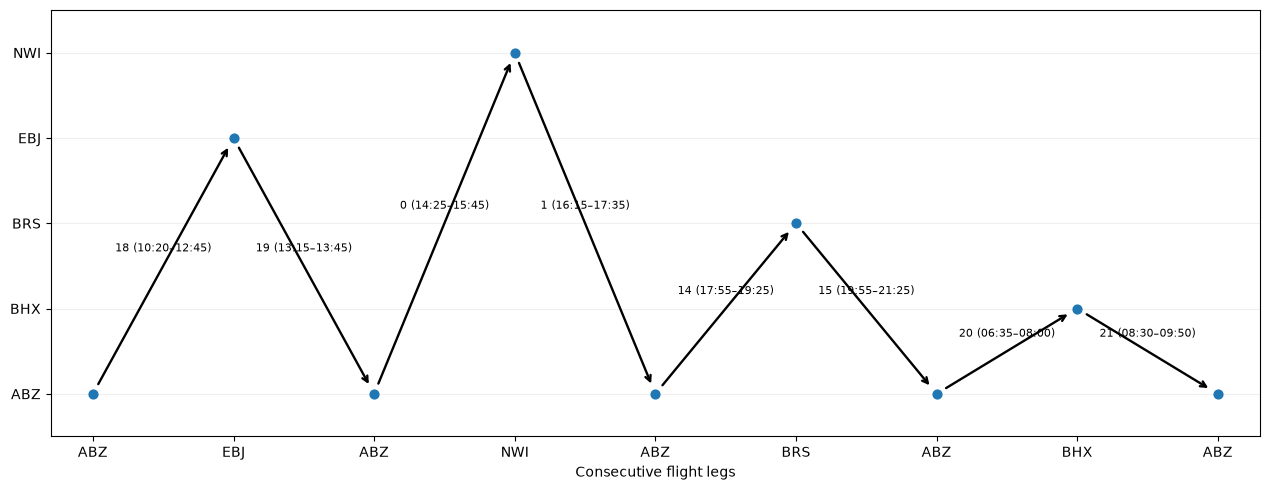

In [12]:
plot_cycle(cycles[0], F)

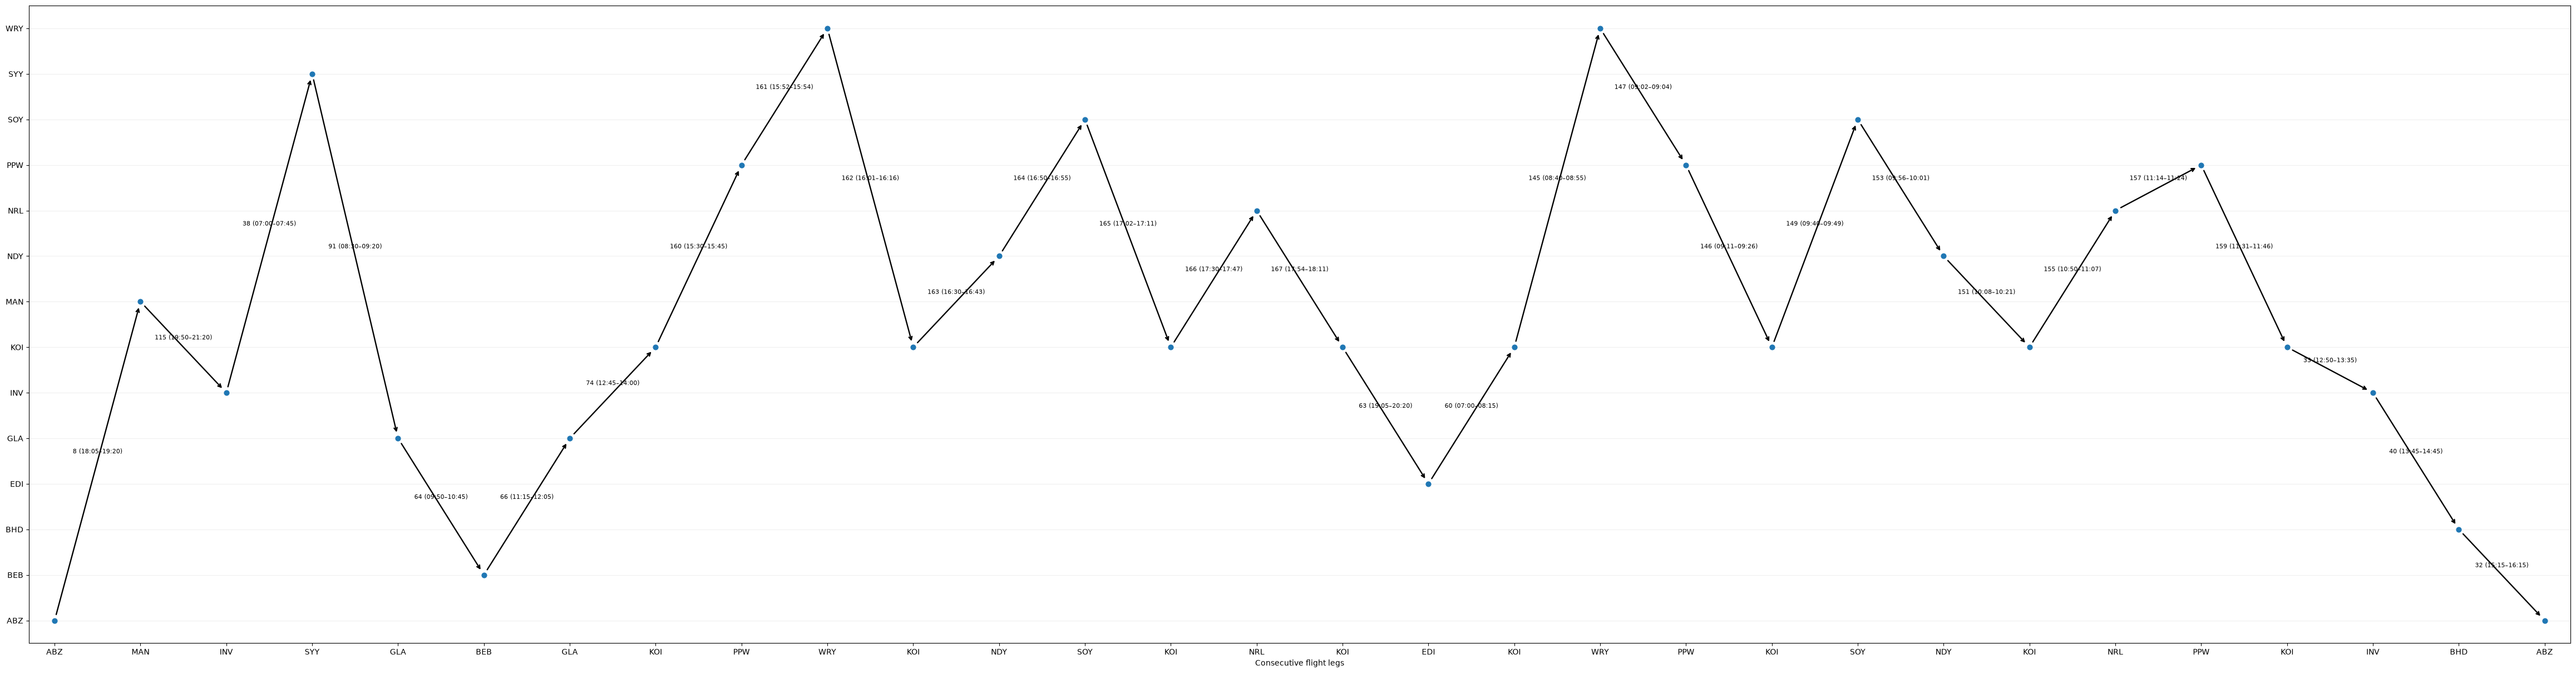

In [13]:
plot_cycle(cycles[1], F)

## Turnaround Time

In the optimal solution, the time between arrival and the next departure within a cycle can be as short as 10 minutes. This suggests that, in some cases, an aircraft may have only 10 minutes to prepare for its next flight. To address this, we introduce a minimum turnaround time by adding a constant to each arrival time in the set of time-nodes, thereby shifting the corresponding nodes in the network.

In [14]:
turnaround = 30
T = {airport: [] for airport in M}

for f in F:
    T[f["origin"]].append((minutes(f["departure"]), -1, f["id"]))
    T[f["destination"]].append((minutes(f["arrival"]) + turnaround, 1, f["id"]))

for airport in M:
    T[airport].sort(key=lambda event: (event[0], -event[1]))

In [15]:
balance = Counter()

for flight in F:
    balance[flight["origin"]] -= 1
    balance[flight["destination"]] += 1

unbalanced = {m: balance[m] for m in M if balance[m] != 0}

print("Flights:", len(F))
print("Airports with unequal arrivals and departures:", len(unbalanced))

for airport, difference in unbalanced.items():
    print(f"{airport}: {difference:+d}")

if unbalanced:
    print("The cyclic model cannot be feasible with this timetable.")
else:
    print("Daily flight counts are balanced at every airport.")

Flights: 163
Airports with unequal arrivals and departures: 0
Daily flight counts are balanced at every airport.


In [16]:
assignment, total_cost = solve_fleet_assignment(F, K, M, T, distances_km)

if assignment is None:
    print("No optimal fleet assignment was found for the complete schedule.")
else:
    print(f"Total fuel cost: £{total_cost:,.2f}")

    print("\nFlights assigned by aircraft type:")
    counts = Counter(assignment.values())

    for j in K:
        print(f"Type {j}: {counts[j]} flights")

    print("\nAll assignments:")
    for flight in F:
        print(f"Flight {flight['id']}: type {assignment[flight['id']]}")

Solver status: TerminationReason.OPTIMAL
Total fuel cost: £112,707.17

Flights assigned by aircraft type:
Type 1: 26 flights
Type 2: 14 flights
Type 3: 2 flights
Type 4: 63 flights
Type 5: 22 flights
Type 6: 24 flights
Type 7: 12 flights

All assignments:
Flight 0: type 6
Flight 1: type 6
Flight 2: type 6
Flight 3: type 6
Flight 4: type 6
Flight 5: type 6
Flight 6: type 6
Flight 7: type 6
Flight 8: type 2
Flight 9: type 2
Flight 10: type 4
Flight 11: type 4
Flight 12: type 4
Flight 13: type 4
Flight 14: type 6
Flight 15: type 6
Flight 16: type 4
Flight 17: type 4
Flight 18: type 6
Flight 19: type 6
Flight 20: type 6
Flight 21: type 6
Flight 22: type 6
Flight 23: type 6
Flight 24: type 2
Flight 25: type 2
Flight 26: type 4
Flight 27: type 3
Flight 29: type 3
Flight 30: type 4
Flight 31: type 2
Flight 32: type 2
Flight 33: type 4
Flight 34: type 4
Flight 35: type 4
Flight 36: type 4
Flight 37: type 4
Flight 38: type 4
Flight 39: type 4
Flight 40: type 2
Flight 41: type 2
Flight 43: type 

We found that the problem becomes infeasible for turnaround times greater than 30 minutes. This is because longer turnaround times increase the number of aircraft required to operate all scheduled flights, eventually exceeding the available fleet size.

In [17]:
aircraft_type = 4

cycles = find_aircraft_cycles(F, T, assignment, aircraft_type)

print(f"Aircraft type: {aircraft_type}")
print(f"Number of cycles: {len(cycles)}")

for i, cycle in enumerate(cycles):
    print(f"Cycle {i + 1}: {len(cycle)} flights — {cycle}")

Aircraft type: 4
Number of cycles: 9
Cycle 1: 4 flights — ['16', '17', '26', '30']
Cycle 2: 4 flights — ['36', '34', '160', '146']
Cycle 3: 4 flights — ['80', '79', '84', '89']
Cycle 4: 4 flights — ['108', '105', '106', '107']
Cycle 5: 6 flights — ['112', '103', '104', '109', '110', '111']
Cycle 6: 8 flights — ['67', '68', '69', '72', '73', '90', '91', '65']
Cycle 7: 8 flights — ['124', '141', '142', '137', '138', '139', '140', '123']
Cycle 8: 10 flights — ['11', '75', '74', '12', '13', '166', '144', '149', '165', '10']
Cycle 9: 15 flights — ['143', '156', '161', '147', '158', '33', '37', '114', '113', '115', '38', '39', '35', '155', '167']


In [18]:
flight_data = {f["id"]: f for f in F}

cycle = cycles[7]

for flight_id in cycle:
    f = flight_data[flight_id]
    print(
        f"{f['origin']} -> {f['destination']}  "
        f"{f['departure']}–{f['arrival']}  "
        f"(ID: {flight_id})"
    )

ABZ -> KOI  08:50–09:45  (ID: 11)
KOI -> GLA  10:15–11:25  (ID: 75)
GLA -> KOI  12:45–14:00  (ID: 74)
KOI -> ABZ  14:30–15:20  (ID: 12)
ABZ -> KOI  15:50–16:45  (ID: 13)
KOI -> NRL  17:30–17:47  (ID: 166)
NRL -> KOI  07:59–08:16  (ID: 144)
KOI -> SOY  09:40–09:49  (ID: 149)
SOY -> KOI  17:02–17:11  (ID: 165)
KOI -> ABZ  07:30–08:20  (ID: 10)


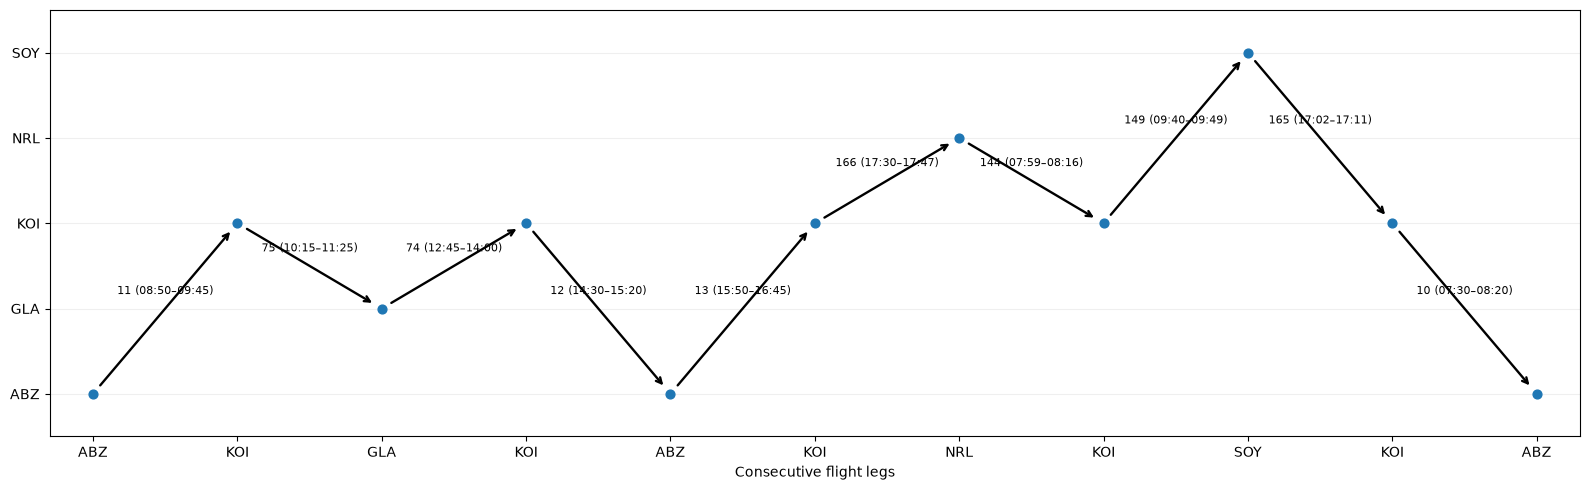

In [19]:
plot_cycle(cycles[7], F)

## Saving into file

In [20]:
def export_assignment(assignment, output_file="flights_assigned.csv"):
    # Aircraft type -> model
    models = {}
    with open("aircraft_data.csv", encoding="utf-8-sig", newline="") as file:
        for row in csv.DictReader(file):
            if row["Type No"]:
                models[int(row["Type No"])] = f'{row["Manufacturer"]} {row["Model"]}'

    # Read flights and append the assigned aircraft model
    with open("flights.csv", encoding="utf-8-sig", newline="") as file:
        reader = csv.DictReader(file)
        fieldnames = reader.fieldnames + ["aircraft_assigned"]
        rows = list(reader)

    for row in rows:
        if row["id"] not in ["28","42","49","92","118"]:
            aircraft_type = assignment[row["id"]]
            row["aircraft_assigned"] = models[aircraft_type]

    # Write the result
    with open(output_file, "w", encoding="utf-8-sig", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(rows)

    print(f"Exported {len(rows)} flights to {output_file}")

In [21]:
if assignment is not None:
    export_assignment(assignment, "flights_assigned.csv")

Exported 168 flights to flights_assigned.csv


## Comparison of Assignment with and without  30min Turnaround Time

In [28]:
# Assigned Flights without turnaround time

no_turnaround = []
with open("flights_assigned_no_turnaround.csv", encoding="utf-8-sig", newline="") as file:
    for row in csv.DictReader(file):
        no_turnaround.append({
            "id": row["id"],
            "origin": row["origin"],
            "destination": row["destination"],
            "departure": row["departure"],
            "arrival": row["arrival"],
            "aircraft assigned": row["aircraft_assigned"],
        })

turnaround = []
with open("flights_assigned.csv", encoding="utf-8-sig", newline="") as file:
    for row in csv.DictReader(file):
        no_turnaround.append({
            "id": row["id"],
            "origin": row["origin"],
            "destination": row["destination"],
            "departure": row["departure"],
            "arrival": row["arrival"],
            "aircraft assigned": row["aircraft_assigned"],
        })

            

FileNotFoundError: [Errno 2] No such file or directory: 'flights_assigned_no_turnaround.csv'